# Final project · Your FoodBridge system

In Weeks 2–8 you built the parts of an information system one by one. Now you put them together into **your own** system: it runs a day of offers, follows **your** decisions, and you can explain and hand over every choice.

| Level | What you do | Required? |
|---|---|---|
| **1 · Run it** | Run the complete system with the default settings and check that it is healthy. | ⭐ Required |
| **2 · Make it yours** | Make at least 3 decisions in `MY_SETTINGS` and explain them in a decision log. No new code is needed. | ⭐ Required |
| **3 · Extend** | Plug in your own functions (rules, checks, reports) and protect them with tests. | ⭐⭐ Optional |
| **4 · Web page** | Open your system as a web page, and download it to run on your own computer. | ⭐⭐ Optional |

Levels 1 and 2 are the **minimum**: everyone can finish them, because they need settings, not new code. Levels 3 and 4 are for students who want to go further. Higher marks come from the **quality of your decisions and explanations**, not from the amount of code.

*Campus FoodBridge is fictional. All organisations, people and numbers are invented.*

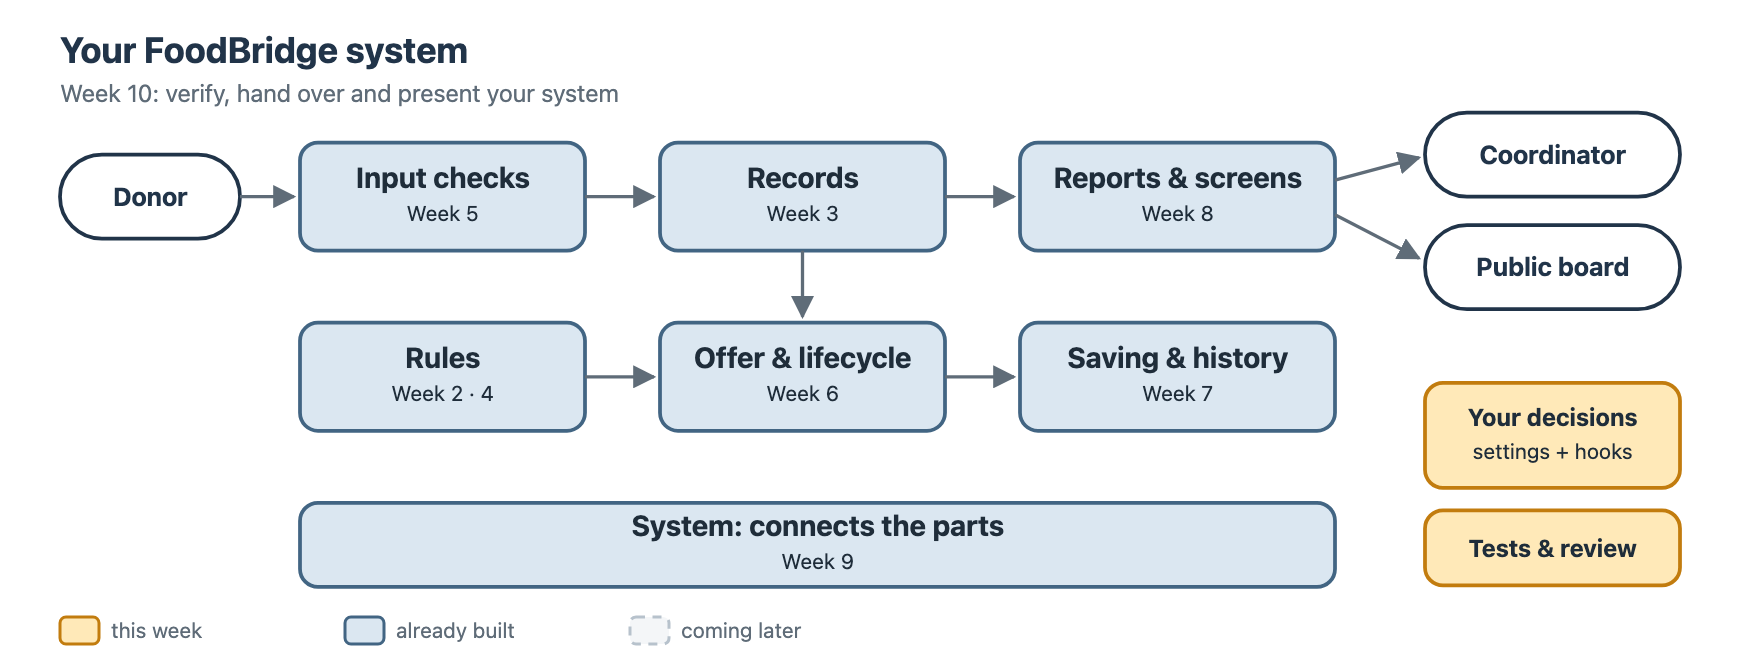

## 0 · Start

1. Click **Copy to Drive** (or **File → Save a copy in Drive**), then work in your copy.
2. Run the setup cell. Run it again after every runtime restart.
3. Work from top to bottom. Before you submit, use **Runtime → Restart session and run all**.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the FoodBridge system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.3"
_KIT_SHA = "9a7f0e70ab94bb1480312c1ccc2cd08ea21038ab8fa51cc0adbfe520961d0844"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("foodbridge_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("foodbridge_kit/my_settings.py", "foodbridge_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("foodbridge_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "foodbridge" or m.startswith("foodbridge.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import foodbridge as bridge
print("✅ FoodBridge system ready (version " + bridge.KIT_VERSION + "). You can continue.")


## Level 1 · Run it ⭐

This is the whole system with the default settings. Nothing here uses your code yet, so it cannot break.

In [ ]:
system = bridge.System()
system.run_day()

Two people use this system and see different things. Read both views.

In [ ]:
print(system.report("coordinator"))
print()
print(system.report("public"))

`verify()` runs the kit's own checks. Every line in the first part must show ✅.

In [ ]:
system.verify()

📝 **Level 1 · In your own words** (2–3 sentences): who uses this system, what data does it keep, and what is one rule it follows?

**My answer:** …

## Level 2 · Make it yours ⭐

### Your decisions

Below is **every decision** the system lets you change, with the week you met it (two are new: `PARTNERS` and `LANGUAGE`). Remove the `#` in front of a line to change it.

You must make **at least 3 decisions**: change a value, or keep a default on purpose and explain why. **At least one** must be about **privacy** (`PUBLIC_FIELDS`) or **input checks** (`REQUIRED_FIELDS`, `MIN_PORTIONS`, `MAX_PORTIONS`, `REJECT_IF_HOURS_LEFT_BELOW`, `CATEGORIES`). `SYSTEM_NAME` is only a name: change it if you like, but it does not count as one of your 3 decisions.

In [ ]:
MY_SETTINGS = {
    "SYSTEM_NAME": "Campus FoodBridge",                    # Week 1 · a name only (not a decision)
    # "TEAM_PICKUP_MIN_PORTIONS": 20,                       # Week 2 · this many portions or more → team
    # "URGENT_HOURS": 3,                                    # Week 2 · hours left at or below → urgent
    # "SOON_HOURS": 12,                                     # Week 2 · hours left at or below → soon
    # "CATEGORIES": ["bread", "rice meals", "fruit", "vegetables", "snacks"],  # Week 3
    # New · the partners a coordinator can choose:
    # "PARTNERS": ["Hope Children's Centre", "Riverside Community Kitchen", "Old Market Elders' Group"],
    # "REQUIRED_FIELDS": ["donor", "food", "category", "portions", "hours_left"],  # Week 5
    # "MIN_PORTIONS": 1,                                    # Week 5
    # "MAX_PORTIONS": 200,                                  # Week 5
    # "REJECT_IF_HOURS_LEFT_BELOW": 1,                      # Week 5 · too late to collect
    # "REQUIRE_APPROVAL": True,                             # Week 6 · a coordinator approves first
    # "LOG_EVENTS": ["added", "input_rejected", "moved"],   # Week 7 · what the history keeps
    # "PUBLIC_FIELDS": ["id", "food", "category", "portions", "status"],  # Week 8 · privacy
    # "REPORT_SORT": "urgency",                             # Week 8 · "urgency", "portions" or "id"
    # "LANGUAGE": "en",                                     # New · "en" or "km" (Khmer words)
}

### Your functions (optional at Level 2, needed for Level 3)

If you finished functions in Weeks 2–8, you can plug them in as **hooks**. Paste a function into the cell below, with any helper or dictionary it uses, then add it to `MY_HOOKS`. If you leave `MY_HOOKS` empty, the system uses its own default rules, and that is fine for Level 2.

Read every number from `ALL_SETTINGS` (the cell makes it for you: your settings plus the defaults). **Delete any `NAME = value` lines you paste** from earlier weeks, such as `TEAM_PICKUP_MIN_PORTIONS = 20`. Otherwise your function and your settings can disagree.

| Hook | Week | What it decides |
|---|---|---|
| `pickup_label(portions, approved)` | 2 | hold, team or standard |
| `urgency(hours_left)` | 2 | urgent, soon or later |
| `clean_offer(raw)` | 5 | accept or refuse an offer, with messages |
| `can_move(old_status, new_status)` | 6 | which status changes are allowed |
| `public_row(record)` | 8 | what the public board shows |

In [ ]:
ALL_SETTINGS = bridge.make_settings(MY_SETTINGS, quiet=True)  # every setting: yours, or the default

# Paste your functions here, with any helpers they use, for example:
#
# TEAM_PICKUP_MIN_PORTIONS = ALL_SETTINGS["TEAM_PICKUP_MIN_PORTIONS"]   # from your settings
#
# def pickup_label(portions, approved):
#     ...

MY_HOOKS = {
    # "pickup_label": pickup_label,
}

### Run your system

In [ ]:
my_system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS)
my_system.run_day()
print(my_system.report("coordinator"))
print()
print(my_system.report("public"))

`verify()` now also reports **your** system: what you changed, which hooks are plugged in, and any warnings. The second part is not pass/fail. It is there so you can explain it.

In [ ]:
my_system.verify()

### Try one offer

Some decisions change nothing in the sample day. For example, a team minimum of 25 gives the same labels as 20, because no open offer has between 20 and 24 portions. So try **one offer of your own**. The cell below adds it to a new, empty test system twice: once with the default settings, once with yours. Your real system does not change.

Change the values in `try_row` until the two lines differ because of **your** decision. Ideas: portions between 20 and your team minimum · portions above your `MAX_PORTIONS` · a category you removed · hours left equal to your `URGENT_HOURS`.

In [ ]:
def try_offer(settings, hooks, row):
    """Add one row to a new, empty test system, approve it, and say what happened."""
    test_system = bridge.System(settings, hooks=hooks, quiet=True)
    offer_id, errors = test_system.add_offer(row)
    if offer_id is None:
        return "refused: " + " ".join(errors)
    offer = test_system.get(offer_id)
    before = test_system.label(offer)
    test_system.move(offer_id, "approved", partner=test_system.settings["PARTNERS"][0])
    return ("accepted · urgency: " + test_system.urgency(offer)
            + " · pickup: " + before + ", after approval: " + test_system.label(offer))

In [ ]:
try_row = {"donor": "Test Donor", "contact": "test@example.org", "food": "Rice boxes",
           "category": "rice meals", "portions": "22", "hours_left": "6"}

print("Default system:", try_offer({}, {}, try_row))
print("My system:     ", try_offer(MY_SETTINGS, MY_HOOKS, try_row))

🤔 Compare with Level 1, and use **Try one offer**. Which offer was treated differently because of your decisions? Point at one line in the output.

**My answer:** …

### 📝 Decision log

One row per decision. A strong entry names a **specific value**, a **real alternative**, a **reason tied to people**, and **who is affected** (the tradeoff).

| Setting | My value | An alternative I considered | Why I chose it | Who is affected (the tradeoff) |
|---|---|---|---|---|
| | | | | |
| | | | | |
| | | | | |

<details><summary>Show an example of a strong entry</summary>

| Setting | My value | An alternative I considered | Why I chose it | Who is affected (the tradeoff) |
|---|---|---|---|---|
| `PUBLIC_FIELDS` | id, food, portions, status | also show `category` | Partners only need to know what food is coming and how much. Fewer fields means less to leak. | Partners cannot filter by category; donors' details stay private. |

A weak entry says only "I changed it to 25 because it is better." Better for whom, and what is lost?

</details>

## Level 3 · Extend ⭐⭐ (optional)

Add something the system does not do yet, and **protect it with tests**. Choose one idea, or your own:

- **A smarter rule:** a `pickup_label` or `urgency` hook that also uses another value you decide, written with named constants.
- **A stricter check:** a `clean_offer` hook that refuses something new (for example, food names shorter than 3 letters), with a clear message. You do not need to rewrite Week 5: start from the kit's own check and add one rule (see below).
- **An honest number:** a report function such as `rejected_or_cancelled_percent(records)`: what share of offers were rejected or cancelled? (Rows *refused at the door* are a different measure: they never became offers.)
- **A new status:** add a state such as `"reserved"` to your own `ALLOWED_MOVES` and `can_move`, and explain who would use it. ⚠️ **Known limit:** the kit's reports know only the six statuses. A reserved offer disappears from the coordinator view and from *Portions still open*. Write a test that shows this (see below), and list it under *Known limits* in your handoff note.

<details><summary>Show a start for a stricter check</summary>

```python
def clean_offer(raw):
    """The kit's checks (with my settings), plus one rule of my own."""
    offer, errors = bridge.validation.clean_offer(raw, ALL_SETTINGS)
    if offer is not None and len(offer["food"]) < 3:
        return None, ["food name must have at least 3 letters."]
    return offer, errors
```

`ALL_SETTINGS` comes from the hook cell in Level 2. Add `"clean_offer": clean_offer` to `MY_HOOKS`, run `bridge.check("clean_offer", clean_offer, MY_SETTINGS)`, and write two tests: a 3-letter food name is accepted, a 2-letter one is refused.

</details>

<details><summary>Show a test for the "reserved" limit</summary>

```python
def test_reserved_offer_leaves_the_coordinator_view():
    system = bridge.System(hooks={"can_move": can_move}, quiet=True)  # your can_move, with "reserved"
    system.run_day(show=False)
    ok, message = system.move("F004", "reserved")
    assert ok, "my lifecycle allows approved -> reserved: " + message
    report = system.report("coordinator")
    assert "F004" not in report, "known limit: the coordinator view shows only new, approved and picked_up"
```

This test passes while the limit exists. It does not hide the problem: it **documents** it, so the next person knows.

</details>

Write your function, then at least **two** `test_` functions (a normal case and a boundary or odd case). Put your tests in the list `MY_TESTS`; the cell after it runs each one, as in Week 10. A test that is not written yet shows ❌ on purpose.

In [ ]:
def rejected_or_cancelled_percent(records):
    """Return the share of offers that were rejected or cancelled, as a whole percentage."""
    return None   # TODO (or replace this with your own idea)


def test_percent_on_sample_records():
    assert False, "not written yet: use bridge.sample_records()"


def test_percent_on_empty_list():
    assert False, "not written yet: what should an empty list give?"


MY_TESTS = [test_percent_on_sample_records, test_percent_on_empty_list]
print(rejected_or_cancelled_percent(my_system.records()))

In [ ]:
for test in MY_TESTS:
    try:
        test()
        print("✅", test.__name__)
    except Exception as error:
        print("❌", test.__name__, "→", type(error).__name__ + ":", error)
print(len(MY_TESTS), "tests run.")

📝 **Level 3 · What I added and why** (who needs it, what you tested, one limit):

**My answer:** …

## Level 4 · Web page ⭐⭐ (optional)

### 4a · Open your system as a web page

Remove the `#` and run the cell. In Colab, a link appears: click it to open your system in a new tab. The page uses **your** settings and hooks. Try adding an offer with bad input, and moving an offer to a status that is not allowed.

In [ ]:
# bridge.start_web(my_system)

The page keeps running while the notebook is open. If you run 4a again, it restarts with your latest system. To stop it, remove the `#` below and run the cell. Then put the `#` back.

In [ ]:
# bridge.stop_web()

### 4b · Download your system and run it at home

This makes a ZIP of the whole system with **your** decisions written into `my_settings.py` and your hooks into `my_rules.py`. Remove the `#` and run it.

In [ ]:
# bridge.download_my_system(MY_SETTINGS, MY_HOOKS)

**On your own computer** (Python 3.9 or newer; nothing to install):

1. Unzip `my_foodbridge.zip`.
2. Open a terminal in the `foodbridge_kit` folder.
3. Run `python run_web.py` (on some computers `python3 run_web.py`) and open http://localhost:8000.
4. Other commands: `python run_menu.py` (a text menu), `python run_tests.py` (the kit's tests).

**In Colab's terminal** (if your Colab has the **Terminal** button at the bottom left):

1. Run 4b first. It already writes `my_foodbridge.zip` into the Files panel (📁 on the left), so you do not need to upload anything.
2. In the terminal, type these commands one at a time: `unzip -o -q my_foodbridge.zip -d home_copy`, then `cd home_copy/foodbridge_kit`, then `python run_menu.py`.
3. For the web page: if you ran 4a, first run `bridge.stop_web()` in the notebook. Then type `python run_web.py` in the terminal (still in `home_copy/foodbridge_kit`). Then remove the `#` in the cell below, run it, and click the link. If `run_web.py` prints a different port number, use that number instead of 8000.

In [ ]:
# bridge.web_link(8000)

Your saved offers are kept in the `saved_data` folder next to `run_web.py`. To start a fresh day, run `python run_web.py --fresh` (or `python run_menu.py --fresh`).

## 5 · Verify and hand over ⭐

A system is finished when **someone else** can run it and trust it.

1. **Runtime → Restart session and run all.** Every cell should run, top to bottom, with no error.
2. Paste your two decision tests from Week 10 into **Tests for my decisions**. Both must show ✅.
3. Run the **Final check** one last time.

### Tests for my decisions

These helpers are the same as in Week 10. Run the cell; you do not need to change it.

In [ ]:
ALL_SETTINGS = bridge.make_settings(MY_SETTINGS, quiet=True)  # every setting: yours, or the default


def fresh_system():
    """Return a new system with my settings and hooks, after the sample day."""
    system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS, quiet=True)
    system.run_day(show=False)
    return system


def offer_row(system, portions):
    """Return a raw offer row that passes every input check (portions may be changed)."""
    return {"donor": "Test Donor", "contact": "test@example.org", "food": "Test rice",
            "category": system.settings["CATEGORIES"][0], "portions": str(portions),
            "hours_left": "8"}


def approved_offer(system, portions):
    """Add a test offer, approve it for the first partner, and return the Offer."""
    offer_id, errors = system.add_offer(offer_row(system, portions))
    assert offer_id is not None, "the test offer was refused: " + "; ".join(errors)
    system.move(offer_id, "approved", partner=system.settings["PARTNERS"][0])
    return system.get(offer_id)


def run_tests(tests):
    passed = 0
    for test in tests:
        try:
            test()
            print("✅", test.__name__)
            passed = passed + 1
        except Exception as error:
            print("❌", test.__name__, "→", type(error).__name__ + ":", error)
    print(passed, "of", len(tests), "tests passed")

Paste the two tests you wrote in Week 10 (P2) into the cell below, in place of the two placeholders. Then put their names in `MY_DECISION_TESTS`. Each test protects one of **your** decisions. A test that is not written yet shows ❌ on purpose.

In [ ]:
def test_my_decision_one():
    system = fresh_system()
    assert False, "not written yet: paste your first Week 10 test here"


def test_my_decision_two():
    system = fresh_system()
    assert False, "not written yet: paste your second Week 10 test here"


MY_DECISION_TESTS = [test_my_decision_one, test_my_decision_two]
run_tests(MY_DECISION_TESTS)

### Final check

`verify()` checks the kit, then reports on **your** system. Read the second part: every ⚠️ needs one sentence in your handoff note.

In [ ]:
final_system = bridge.System(MY_SETTINGS, hooks=MY_HOOKS)
final_ok = final_system.verify()
print()
if final_ok:
    print("Next: read 'Your system' above, and explain every ⚠️ in your handoff note.")
else:
    print("❌ The kit itself is damaged: get a fresh copy of this notebook.")
changed = bridge.settings.changed_settings(final_system.settings)
print("Settings you changed:", ", ".join(changed) or "none")
print("Your hooks:", ", ".join(final_system.custom_hooks()) or "none (default rules)")

### 📝 Handoff note

Write this for a new coordinator who has never seen your notebook. You drafted it in Week 10; copy the final text here.

| | |
|---|---|
| **What my system does** (2 sentences: who uses it, for what) | |
| **How to run it** (numbered steps; say what the operator should see at the end) | 1. <br> 2. <br> 3. |
| **My decisions** (the 3 most important: setting, value, and why) | |
| **What I tested, and how** (my decision tests, the clean run) | |
| **Known limits** (what it does not do; any ⚠️ and why it is acceptable) | |

### 📝 Peer test record (Week 10, Session 2)

A classmate (the operator) runs your system using only your handoff note. You watch and do not help. Copy a short summary of the operator's record here.

| | |
|---|---|
| **Operator's name** | |
| **Could they run it from the note alone? Did you have to speak?** | |
| **The first difficulty** | |
| **Result of `verify()` at the end** | |
| **One change you made to the note** | |
| **Retested after the change? Result** | |

## 6 · Submit

- [ ] Level 1: `verify()` shows ✅ for every kit check.
- [ ] Level 2: at least 3 decisions in `MY_SETTINGS` (one about privacy or input checks; `SYSTEM_NAME` does not count), and a decision log row for each.
- [ ] Level 3 (optional): my function and at least two tests, all ✅.
- [ ] Level 4 (optional): I opened the web page or ran my system from the ZIP.
- [ ] 5: my two decision tests show ✅; handoff note and peer test record filled in; **Runtime → Restart session and run all** done before saving.

Download this notebook (**File → Download → Download .ipynb**) and email it to **submit.progmis@gmail.com**. The deadline and file name will be announced in class.

**Presentation (Week 10, Session 2, 3 minutes):** the people and the problem · your decisions · a short demo · what you tested · what you would improve next.